# Text and Categorical Cleaning (Advanced)

Categorical columns that humans type or that come from several systems contain the same value in many spellings: `São Paulo`, `Sao Paulo`, `sao paulo `, `S. Paulo`. A model treats each spelling as a different category, which splits the data and creates rare, noisy categories. This lesson builds a cleaning workflow and **measures** its accuracy.

**After this lesson you can:**

1. Normalise text: case, whitespace, Unicode (accents), punctuation.
2. Map variants to canonical values with dictionaries and fuzzy matching.
3. Group rare categories and handle multi-valued fields.
4. Measure cleaning accuracy against known truth and review the uncertain cases.

**Data:** the real city and country names of the Chinook customers (accents included), with typing errors added by a documented, seeded generator.

In [1]:
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.model_selection import KFold, StratifiedKFold, cross_val_score

sys.path.insert(0, str(Path.cwd().parent / "tools"))
import datasets                                   # course helper: downloads pinned public datasets

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 100})
RNG = 42

import difflib
import re
import sqlite3
import unicodedata

with sqlite3.connect(datasets.fetch("chinook.sqlite")) as con:
    places = pd.read_sql("SELECT c.City AS city, c.Country AS country FROM Invoice i JOIN Customer c USING (CustomerId)", con)
canonical = sorted(places["city"].unique())
print(f"{len(places)} invoices, {len(canonical)} distinct cities, e.g. {[c for c in canonical if not c.isascii()][:6]}")

412 invoices, 53 distinct cities, e.g. ['Brasília', 'Montréal', 'São José dos Campos', 'São Paulo']


## 1. Create Realistic Messy Input

The generator imitates typical sources of variation: lower/upper case, extra spaces, missing accents, abbreviations and one-letter typos. It is seeded, so the truth is known for every row.

In [2]:
def strip_accents(s: str) -> str:
    return "".join(ch for ch in unicodedata.normalize("NFKD", s) if not unicodedata.combining(ch))

def mess_up(name: str, rng) -> str:
    r = rng.random()
    if r < 0.25:
        return name
    if r < 0.40:
        return name.lower()
    if r < 0.55:
        return "  " + name.upper() + " "
    if r < 0.70:
        return strip_accents(name)
    if r < 0.80 and len(name) > 4:
        i = rng.integers(1, len(name) - 1)
        return name[:i] + name[i + 1:]                              # one letter missing
    if r < 0.90 and len(name) > 4:
        i = rng.integers(1, len(name) - 2)
        return name[:i] + name[i + 1] + name[i] + name[i + 2:]      # two letters swapped
    return name.replace("Saint", "St.").replace("São", "S.").replace("ã", "a") + "."

rng = np.random.default_rng(RNG)
data = places.assign(raw=[mess_up(c, rng) for c in places["city"]])
print(f"distinct raw spellings: {data['raw'].nunique()} for {data['city'].nunique()} real cities")
data.sample(8, random_state=1)[["raw", "city"]]

distinct raw spellings: 222 for 53 real cities


,raw,city
258,Frankfurt,Frankfurt
29,prague,Prague
187,Tucson,Tucson
293,Bordeaux.,Bordeaux
261,Berlin,Berlin
197,Tronto,Toronto
358,London,London
218,WINNIPEG,Winnipeg


## 2. Step 1: Normalise

Normalisation maps many variants to one key, without any knowledge of the correct values:

1. Unicode normalisation (NFKC), then remove accents for the **key** (keep the accented canonical value for display),
2. case folding (`casefold()` is stronger than `lower()`, for example for the German ß),
3. remove punctuation, collapse whitespace.

In [3]:
def normalise(s: str) -> str:
    s = unicodedata.normalize("NFKC", s)
    s = strip_accents(s).casefold()
    s = re.sub(r"[^\w\s]", " ", s)
    return re.sub(r"\s+", " ", s).strip()

key_to_canonical = {normalise(c): c for c in canonical}
data["step1"] = data["raw"].map(lambda s: key_to_canonical.get(normalise(s)))
acc1 = (data["step1"] == data["city"]).mean()
print(f"exact match after normalisation: {acc1:.1%} of rows; unresolved: {data['step1'].isna().sum()}")
print("examples resolved:", data.loc[data["step1"].notna() & (data["raw"] != data["city"]), ["raw", "step1"]].head(4).values.tolist())

exact match after normalisation: 80.3% of rows; unresolved: 81
examples resolved: [['Sao Jose dos Campos', 'São José dos Campos'], ['  STUTTGART ', 'Stuttgart'], ['stuttgart', 'Stuttgart'], ['Stuttgart.', 'Stuttgart']]


## 3. Step 2: Abbreviations and Fuzzy Matching

The remaining values have typos or abbreviations. A small **alias dictionary** handles known abbreviations; **fuzzy matching** finds the most similar canonical value for the rest. `difflib.SequenceMatcher` scores similarity between 0 and 1; a threshold decides when a match is trusted, and uncertain matches go to a review list.

In [4]:
ALIASES = {r"\bst\b": "saint", r"^s\b": "sao"}

def expand(key: str) -> str:
    for pattern, repl in ALIASES.items():
        key = re.sub(pattern, repl, key)
    return key

keys = list(key_to_canonical)

def resolve(raw: str, threshold: float = 0.85):
    key = expand(normalise(raw))
    if key in key_to_canonical:
        return key_to_canonical[key], 1.0
    best = difflib.get_close_matches(key, keys, n=1, cutoff=0)
    score = difflib.SequenceMatcher(None, key, best[0]).ratio() if best else 0.0
    return (key_to_canonical[best[0]] if score >= threshold else None), score

res = data["raw"].map(resolve)
data["clean"], data["score"] = res.str[0], res.str[1]
acc = (data["clean"] == data["city"]).mean()
wrong = data[data["clean"].notna() & (data["clean"] != data["city"])]
review = data[data["clean"].isna()]
print(f"correct: {acc:.1%} | wrong matches: {len(wrong)} | sent to review: {len(review)}")
print(wrong[["raw", "clean", "city", "score"]].drop_duplicates().head())
print(review[["raw", "city", "score"]].drop_duplicates().head())

correct: 95.6% | wrong matches: 0 | sent to review: 18
Empty DataFrame
Columns: [raw, clean, city, score]
Index: []
        raw    city     score
37   Prauge  Prague  0.833333
39   Pargue  Prague  0.833333
154  Botson  Boston  0.833333
231  Lsibon  Lisbon  0.833333
235  Lisobn  Lisbon  0.833333


## 4. The Threshold Trade-Off

A low threshold resolves more rows but makes more wrong matches; a high threshold sends more rows to manual review. The cell measures both for a range of thresholds.

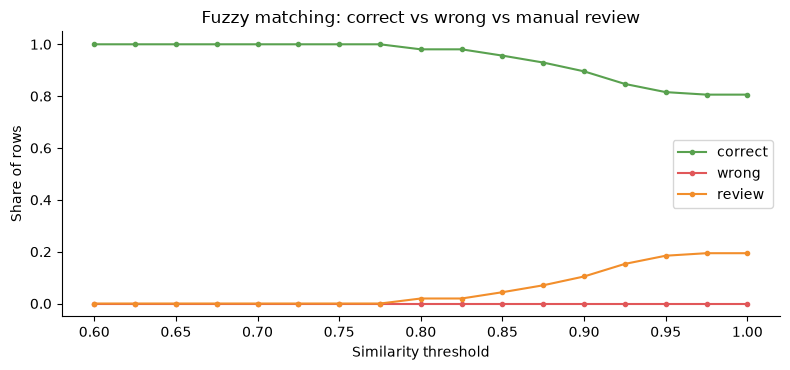

 threshold  correct  wrong  review
       0.6    1.000    0.0   0.000
       0.7    1.000    0.0   0.000
       0.8    0.981    0.0   0.019
       0.9    0.896    0.0   0.104
       1.0    0.806    0.0   0.194


In [5]:
rows = []
for t in np.arange(0.6, 1.001, 0.025):
    out = data["raw"].map(lambda s: resolve(s, t)[0])
    rows.append({"threshold": round(t, 3), "correct": (out == data["city"]).mean(),
                 "wrong": ((out != data["city"]) & out.notna()).mean(), "review": out.isna().mean()})
curve = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(8, 3.8))
for col, c in [("correct", "#59A14F"), ("wrong", "#E15759"), ("review", "#F28E2B")]:
    ax.plot(curve["threshold"], curve[col], marker=".", color=c, label=col)
ax.set(xlabel="Similarity threshold", ylabel="Share of rows", title="Fuzzy matching: correct vs wrong vs manual review")
ax.legend()
plt.tight_layout()
plt.show()
print(curve.iloc[::4].round(3).to_string(index=False))

In this dataset, no threshold produced a wrong match: the 53 city names are very different from each other, so a typo is always closest to the right city. With similar canonical values ("Paris" and "Parma", "Austria" and "Australia"), low thresholds do produce wrong matches. A wrong match is usually worse than a review case, because it silently corrupts the data: choose the threshold where wrong matches stay near zero on a labelled sample, and review the rest.

## 5. Rare Categories and Multi-Valued Fields

After cleaning, group categories that are too rare to learn from, and split fields that contain several values.

In [6]:
counts = data["clean"].value_counts()
rare = counts[counts < 7].index
data["city_model"] = data["clean"].where(~data["clean"].isin(rare), "Other").fillna("Unknown")
print(f"cities: {counts.size} -> {data['city_model'].nunique()} model categories (cities with < 7 invoices -> 'Other')")

tags = pd.Series(["rock; classic rock", "Jazz;blues", "ROCK", "pop ;rock", None])
exploded = tags.str.lower().str.split(r"\s*;\s*").explode().str.strip()
print("\nmulti-valued field -> one-hot tags:")
print(pd.crosstab(exploded.index, exploded))

cities: 53 -> 47 model categories (cities with < 7 invoices -> 'Other')

multi-valued field -> one-hot tags:
col_0  blues  classic rock  jazz  pop  rock
row_0                                      
0          0             1     0    0     1
1          1             0     1    0     0
2          0             0     0    0     1
3          0             0     0    1     1


*Insight: Clean categorical text in layers: normalise (case, spaces, Unicode), apply known aliases, then fuzzy-match against a canonical list with a threshold chosen from measured error rates, and send uncertain cases to review. Keep the mapping as data (a dictionary or table under version control), so the same cleaning runs in production.*

## Real-World Use Case or Analogy

Category cleaning is like **sorting returned letters in a post office**: most addresses only need tidying (normalisation), some use known abbreviations (aliases), some have typos that an experienced clerk can still read (fuzzy matching), and a few go to the "unclear address" desk (review). Delivering a letter to the wrong house is worse than asking.

CRM systems, address databases and product catalogues all need this; "entity resolution" (matching records of the same customer across systems) is a whole field built on these steps.